# Model Evaluation

This notebook evaluates the trained Random Forest and XGBoost classifiers using an independent test dataset.

The evaluation focuses on classification performance, ROC-AUC, confusion matrices, ROC curves, and feature importance.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)

RANDOM_STATE = 42

sns.set_style("whitegrid")

In [3]:
# Load dataset
churn_df = pd.read_csv("../data/processed/cleaned_telco_churn.csv")


X = churn_df.drop(columns=["Churn"])
y = churn_df["Churn"].astype(int)

print("Dataset shape:", churn_df.shape)
print("Target distribution:")
print(y.value_counts())

Dataset shape: (7043, 20)
Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [4]:
# Recreate the original train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (5634, 19)
Testing set: (1409, 19)


In [5]:
# Load the trained models

rf_model = joblib.load("../models/random_forest_churn.pkl")

xgb_model = joblib.load("../models/xgboost_churn.pkl")

print("Both trained models loaded successfully.")

Both trained models loaded successfully.


In [6]:
# Generate predictions

# Random Forest predictions
rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

# XGBoost predictions
xgb_predictions = xgb_model.predict(X_test)
xgb_probabilities = xgb_model.predict_proba(X_test)[:, 1]

In [7]:
# Evaluate both models

evaluation_results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Accuracy": [
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, xgb_predictions)
    ],
    "Precision": [
        precision_score(y_test, rf_predictions),
        precision_score(y_test, xgb_predictions)
    ],
    "Recall": [
        recall_score(y_test, rf_predictions),
        recall_score(y_test, xgb_predictions)
    ],
    "F1-Score": [
        f1_score(y_test, rf_predictions),
        f1_score(y_test, xgb_predictions)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, rf_probabilities),
        roc_auc_score(y_test, xgb_probabilities)
    ]
})

evaluation_results.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7771,0.5974,0.4920,0.5396,0.8202
1,XGBoost,0.7984,0.6372,0.5588,0.5954,0.8440


**Interpretation:** On the held-out test set, XGBoost scores higher than Random Forest on every reported metric: accuracy (0.7984 vs. 0.7771), precision (0.6372 vs. 0.5974), recall (0.5588 vs. 0.4920), F1 (0.5954 vs. 0.5396), and ROC-AUC (0.8440 vs. 0.8202). This makes XGBoost the stronger of these two candidates in this evaluation. Because churn is the minority class, accuracy alone is not sufficient; recall and F1 help show how well the models identify customers who actually churn.

In [8]:
# Generate classification reports

print("RANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    rf_predictions,
    target_names=["No Churn", "Churn"]
))

print("\nXGBOOST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    xgb_predictions,
    target_names=["No Churn", "Churn"]
))

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn       0.83      0.88      0.85      1035
       Churn       0.60      0.49      0.54       374

    accuracy                           0.78      1409
   macro avg       0.71      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409


XGBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.64      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



**Interpretation:** Both models classify customers who stayed more reliably than customers who churned. For the churn class, Random Forest has precision 0.60 and recall 0.49, while XGBoost improves these to 0.64 and 0.56. Thus, XGBoost identifies more true churners and its churn predictions are more often correct, but it still misses roughly 44% of actual churners at the default classification threshold. This trade-off matters if the goal is to prioritize retention outreach; a threshold should be chosen based on the cost of missed churn versus unnecessary outreach.

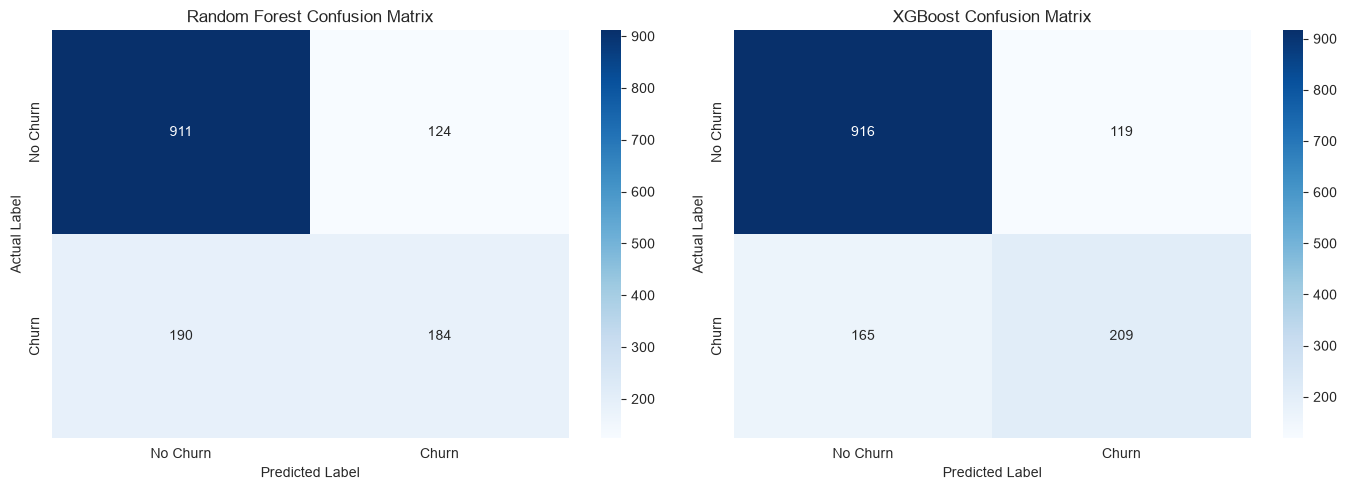

<Figure size 640x480 with 0 Axes>

In [25]:
# Plot confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = [
    ("Random Forest", rf_predictions),
    ("XGBoost", xgb_predictions)
]

for ax, (name, predictions) in zip(axes, models):
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"],
        ax=ax
    )

    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

plt.savefig(
    "../reports/figures/confusion_matrix_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

**Interpretation:** Rows show actual classes and columns show predictions. Random Forest correctly identifies 911 non-churners and 184 churners, but misses 190 churners and raises 124 false churn alerts. XGBoost correctly identifies 916 non-churners and 209 churners, with 165 missed churners and 119 false alerts. XGBoost therefore improves detection of churners while also slightly reducing false alerts. The remaining false negatives show that neither model catches every at-risk customer.

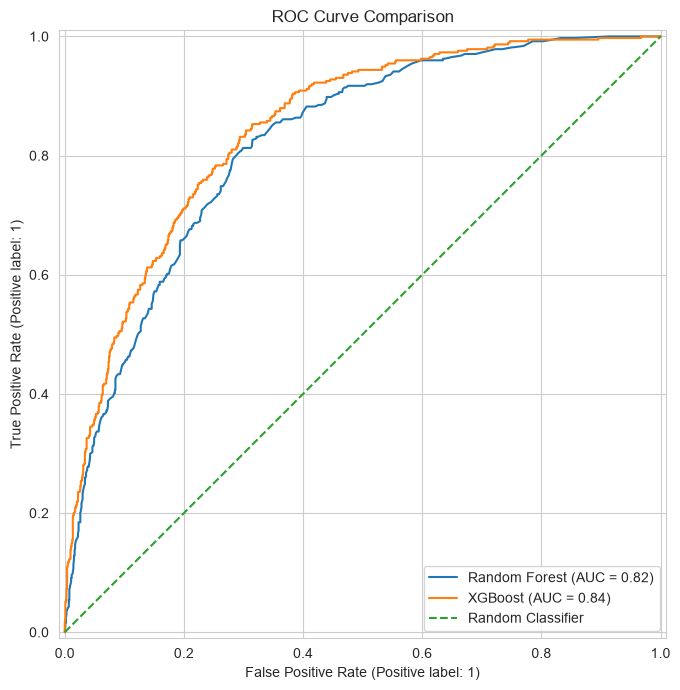

<Figure size 640x480 with 0 Axes>

In [24]:
# Plot ROC-AUC curves
fig, ax = plt.subplots(figsize=(9, 7))

RocCurveDisplay.from_predictions(
    y_test,
    rf_probabilities,
    name="Random Forest",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    xgb_probabilities,
    name="XGBoost",
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

ax.set_title("ROC Curve Comparison")
ax.legend()
plt.tight_layout()
plt.show()

plt.savefig(
    "../reports/figures/roc_curve_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

**Interpretation:** Both ROC curves lie well above the random-classifier diagonal, indicating useful separation between churners and non-churners across classification thresholds. XGBoost has the higher test ROC-AUC (0.844 vs. 0.820), so it ranks churners ahead of non-churners more effectively overall. ROC-AUC summarizes performance across thresholds; it does not determine the operating threshold or guarantee high recall at the default threshold.

### 9. Extract the top 10 influential features


In [11]:
# Retrive feature names

feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

In [12]:
# Create a Random Forest feature-importance table:

rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.named_steps[
        "classifier"
    ].feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

rf_top10 = rf_importance.head(10)

rf_top10

,Feature,Importance
2,num__TotalCharges,0.098080
0,num__tenure,0.083968
37,cat__Contract_Month-to-month,0.080124
1,num__MonthlyCharges,0.079484
44,cat__PaymentMethod_Electronic check,0.062874
19,cat__OnlineSecurity_No,0.061130
28,cat__TechSupport_No,0.056105
22,cat__OnlineBackup_No,0.029623
39,cat__Contract_Two year,0.027630
25,cat__DeviceProtection_No,0.026674


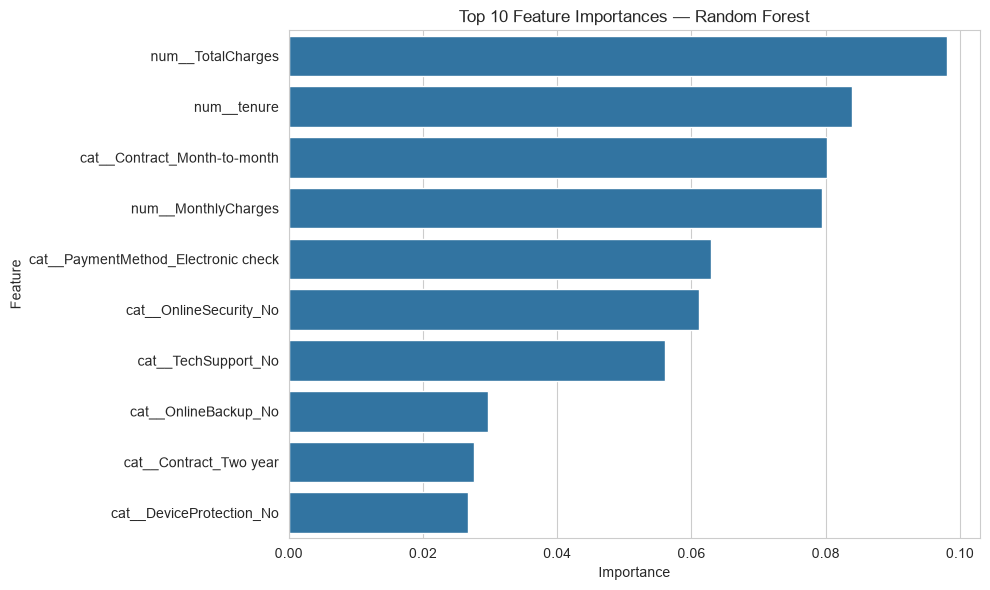

<Figure size 640x480 with 0 Axes>

In [23]:
# Visualize it

plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_top10,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances — Random Forest")
plt.tight_layout()
plt.show()

plt.savefig(
    "../reports/figures/top_10_feature_importance_random_forest.png",
    dpi=300,
    bbox_inches="tight"
)

**Interpretation:** Random Forest places the most importance on `TotalCharges`, `tenure`, month-to-month contract status, and `MonthlyCharges`, followed by electronic-check payment and the absence of online security or tech support. These features help the model distinguish customers in this dataset and broadly align with several patterns seen in the EDA. Importance scores do not show whether a feature raises or lowers churn probability, and they do not establish causation; correlated features can share or shift importance.

In [14]:
# Now the same is done for XGBoost

xgb_feature_names = xgb_model.named_steps[
    "preprocessor"
].get_feature_names_out()

xgb_importance = pd.DataFrame({
    "Feature": xgb_feature_names,
    "Importance": xgb_model.named_steps[
        "classifier"
    ].feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

xgb_top10 = xgb_importance.head(10)

xgb_top10

,Feature,Importance
37,cat__Contract_Month-to-month,0.277110
19,cat__OnlineSecurity_No,0.109662
28,cat__TechSupport_No,0.077605
44,cat__PaymentMethod_Electronic check,0.066649
17,cat__InternetService_Fiber optic,0.049042
22,cat__OnlineBackup_No,0.048239
41,cat__PaperlessBilling_Yes,0.023486
40,cat__PaperlessBilling_No,0.020014
25,cat__DeviceProtection_No,0.018325
9,cat__Dependents_No,0.018112


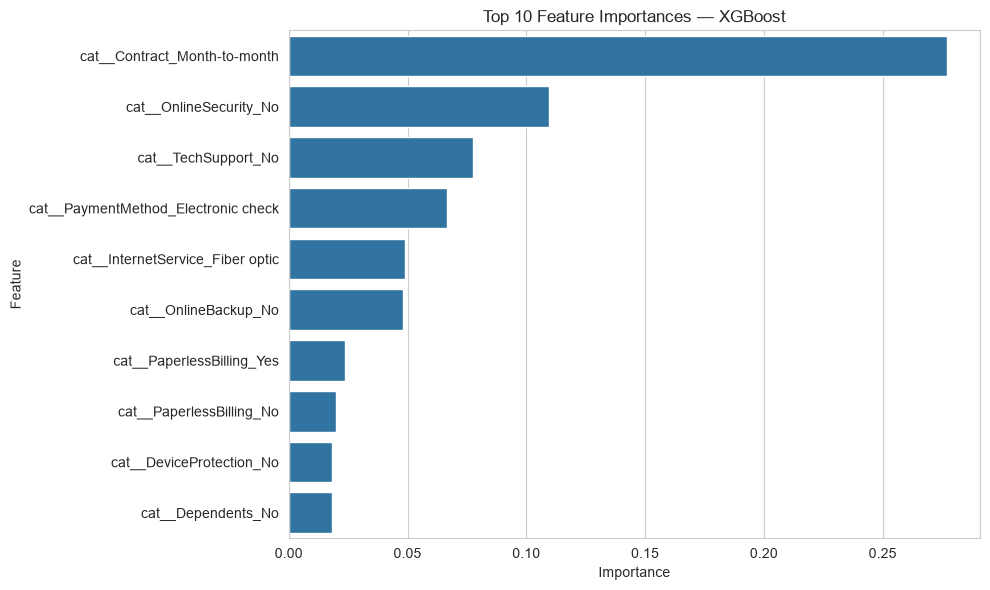

<Figure size 640x480 with 0 Axes>

In [22]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=xgb_top10,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances — XGBoost")
plt.tight_layout()
plt.show()

plt.savefig(
    "../reports/figures/top_10_feature_importance_xgboost.png",
    dpi=300,
    bbox_inches="tight"
)

**Interpretation:** XGBoost assigns the largest importance to month-to-month contracts (0.277), followed by no online security (0.110), no tech support (0.078), electronic-check payment (0.067), and fiber-optic service (0.049). This concentrates more importance on contract type than the Random Forest ranking does. As with the Random Forest plot, importance is a measure of how the fitted model uses features, not a causal explanation or the direction of their effect. Treat these rankings as prompts for further analysis, not standalone reasons for customer-level decisions.

## Overall Conclusion

This notebook recreated the stratified 80/20 train-test split used during model development, loaded the saved Random Forest and XGBoost pipelines, generated churn predictions and probabilities, and evaluated both models on the held-out test set of 1,409 customers. We compared accuracy, precision, recall, F1-score, ROC-AUC, classification reports, confusion matrices, ROC curves, and each model's top feature importances.

XGBoost performed better than Random Forest on every reported test metric: accuracy was 0.7984 versus 0.7771, precision 0.6372 versus 0.5974, recall 0.5588 versus 0.4920, F1-score 0.5954 versus 0.5396, and ROC-AUC 0.8440 versus 0.8202. Its confusion matrix also shows more detected churners (209 versus 184), fewer missed churners (165 versus 190), and slightly fewer false churn alerts (119 versus 124). Based on this test-set comparison, XGBoost is the stronger candidate.

The main limitation is churn recall: XGBoost still misses about 44% of actual churners at the default classification threshold. Before operational use, select and validate a decision threshold based on the relative costs of missed churn and retention outreach, and verify performance on future or otherwise independent data. The feature-importance plots highlight patterns the models use, such as month-to-month contracts and lack of online security or support, but importance scores do not establish causal effects or feature direction.